# Init

In [1]:
import sys
import os
sys.path.insert(1, '../..')

In [2]:
import pandas as pd

# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
df = pd.read_csv(file_path, index_col=0)


# Convert date string column to datetime column
df.index = pd.to_datetime(df.index)

# Set daily frequency
df = df.asfreq('d')

In [3]:
display(df.head())
display(df.describe())

,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date,needed_personal,sby_used_percent,personal_calculated_by_calls,...,month,day_of_week,day_of_month,week_of_year,day_of_year,is_weekend,is_holiday,tavg,tmin,tmax
date,,,,,,,,,,,,,,,,,,,,,
2016-04-01,73,8154.0,1700,90,4.0,0.0,1459468800,1704.0,0.044444,1691.701245,...,4,4,1,13,92,False,False,8.3,5.0,13.1
2016-04-02,64,8526.0,1700,90,70.0,0.0,1459555200,1770.0,0.777778,1768.879668,...,4,5,2,13,93,True,False,9.9,1.3,16.4
2016-04-03,68,8088.0,1700,90,0.0,0.0,1459641600,1700.0,0.000000,1678.008299,...,4,6,3,13,94,True,False,13.1,6.1,19.1
2016-04-04,71,7044.0,1700,90,0.0,0.0,1459728000,1700.0,0.000000,1461.410788,...,4,0,4,14,95,False,False,15.2,9.5,20.6
2016-04-05,63,7236.0,1700,90,0.0,0.0,1459814400,1700.0,0.000000,1501.244813,...,4,1,5,14,96,False,False,16.0,8.4,22.7


,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date,needed_personal,sby_used_percent,personal_calculated_by_calls,...,call_stress,year,month,day_of_week,day_of_month,week_of_year,day_of_year,tavg,tmin,tmax
count,1152.000000,1152.000000,1152.000000,1152.0,1152.000000,1152.000000,1.152000e+03,1152.000000,1152.000000,1152.000000,...,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000
mean,68.808160,7919.531250,1820.572917,90.0,34.718750,16.335938,1.509192e+09,1855.291667,0.385764,1643.056276,...,4.255659,2017.333333,6.424479,3.002604,15.674479,26.023438,180.072049,11.268229,7.051997,15.467882
std,14.293942,1290.063571,80.086953,0.0,79.694251,53.394089,2.874511e+07,117.992747,0.885492,267.648044,...,0.539535,0.977594,3.394101,2.002386,8.778030,14.770423,103.880984,7.711124,6.679351,9.095201
min,36.000000,4074.000000,1700.000000,90.0,0.000000,0.000000,1.459469e+09,1700.000000,0.000000,845.228216,...,2.263333,2016.000000,1.000000,0.000000,1.000000,1.000000,1.000000,-8.800000,-12.800000,-5.800000
25%,58.000000,6978.000000,1800.000000,90.0,0.000000,0.000000,1.484330e+09,1800.000000,0.000000,1447.717842,...,3.875833,2017.000000,4.000000,1.000000,8.000000,14.000000,95.000000,5.200000,1.900000,7.900000
50%,68.000000,7932.000000,1800.000000,90.0,0.000000,0.000000,1.509192e+09,1874.500000,0.000000,1645.643154,...,4.344298,2017.000000,6.000000,3.000000,16.000000,25.000000,174.000000,10.600000,6.700000,14.950000
75%,78.000000,8827.500000,1900.000000,90.0,12.250000,0.000000,1.534054e+09,1900.000000,0.136111,1831.431535,...,4.778991,2018.000000,9.000000,5.000000,23.000000,39.000000,270.000000,17.800000,12.400000,23.000000
max,119.000000,11850.000000,1900.000000,90.0,555.000000,465.000000,1.558915e+09,2455.000000,6.166667,2458.506224,...,4.896288,2019.000000,12.000000,6.000000,31.000000,52.000000,366.000000,28.900000,23.900000,38.000000


In [4]:
def calculate_custom_personal_metrics(df: pd.DataFrame, orig_column : str , pred_column : str, print_results: bool = False) -> dict:

    df = df.copy(deep=True)

    # Berechnung der Unterbesetzung und Überbesetzung
    df['understaffed'] = df[orig_column] > df[pred_column]
    df['overstaffed'] = df[orig_column] < df[pred_column]
    df['perfect'] = df[orig_column] == df[pred_column]
    
    # Anteil an Tagen mit Unterbesetzung
    total_days = len(df)
    understaffed_days = df['understaffed'].sum()
    overstaffed_days = df['overstaffed'].sum()
    perfect_days = df['perfect'].sum()
    
    # Durchschnittliche Über- und Unterbesetzung
    avg_understaffing = (df[orig_column] - df[pred_column])[df['understaffed']].mean()
    avg_overstaffing = (df[pred_column] - df[orig_column])[df['overstaffed']].mean()
    median_understaffing = (df[orig_column] - df[pred_column])[df['understaffed']].median()
    median_overstaffing = (df[pred_column] - df[orig_column])[df['overstaffed']].median()

    # Tagesdurchschnitt Ersatzfahrer für pred_column über die ganze Zeit
    avg_replacement_drivers_pred = df[pred_column].mean()
    
    # Differenz Tagesdurchschnitt Ersatzfahrer für pred_column zu Summe bei orig
    avg_replacement_drivers_orig = df[orig_column].mean()
    difference_avg_replacement_drivers = (avg_replacement_drivers_pred - avg_replacement_drivers_orig).mean()

    results = {
        'Anteil an Tagen mit Unterbesetzung (%)': understaffed_days / total_days * 100,
        'Anteil an Tagen mit Überbesetzung (%)': overstaffed_days / total_days * 100,
        'Anteil an Tagen mit perfekter Prediction (%)': perfect_days / total_days * 100,
        'Durchschnittliche Überbesetzung': avg_overstaffing,
        'Durchschnittliche Unterbesetzung': avg_understaffing,
        'Median Überbesetzung': median_overstaffing,
        'Median Unterbesetzung': median_understaffing,
        'Tagesdurchschnitt Ersatzfahrer für Planung': avg_replacement_drivers_pred,
        'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': difference_avg_replacement_drivers
    }

    if print_results:
        print(f'Results: - ' + ', '.join(f'{key}: {value}' for key, value in results.items()))

    return results


display("Aktueller Stand der Metriken mit festem n_sby:")
display(calculate_custom_personal_metrics(df, "sby_need", "n_sby", print_results=False))

display("Stand, wenn man dynamisch aus Calls berechnet:")
display(calculate_custom_personal_metrics(df, "sby_need", "sby_need_calculated_by_calls", print_results=False))

'Aktueller Stand der Metriken mit festem n_sby:'

{'Anteil an Tagen mit Unterbesetzung (%)': 14.84375,
 'Anteil an Tagen mit Überbesetzung (%)': 84.89583333333334,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.26041666666666663,
 'Durchschnittliche Überbesetzung': 84.35889570552148,
 'Durchschnittliche Unterbesetzung': 110.05263157894737,
 'Median Überbesetzung': 90.0,
 'Median Unterbesetzung': 86.0,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 90.0,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': 55.28125}

'Stand, wenn man dynamisch aus Calls berechnet:'

{'Anteil an Tagen mit Unterbesetzung (%)': 11.71875,
 'Anteil an Tagen mit Überbesetzung (%)': 15.364583333333334,
 'Anteil an Tagen mit perfekter Prediction (%)': 72.91666666666666,
 'Durchschnittliche Überbesetzung': 10.454649881613689,
 'Durchschnittliche Unterbesetzung': 10.69309973874298,
 'Median Überbesetzung': 9.082987551867063,
 'Median Unterbesetzung': 9.336099585062357,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 35.07196576763483,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': 0.3532157676348291}

# Baseline Model

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

target_column_name = "sby_need"

train_size = int(len(df) * 0.8)
train, test = df.iloc[:train_size], df.iloc[train_size:]

# Baseline-Modell: Durchschnitt der Zielvariable im Trainingsset
baseline_pred = train[target_column_name].mean()

print("Mean-Value of train data", baseline_pred)

test = test.copy()

test['baseline_pred'] = baseline_pred


Mean-Value of train data 29.99457111834962


$R^2=-0.05$
$MAE=65.66$
$RMSE=108.90$


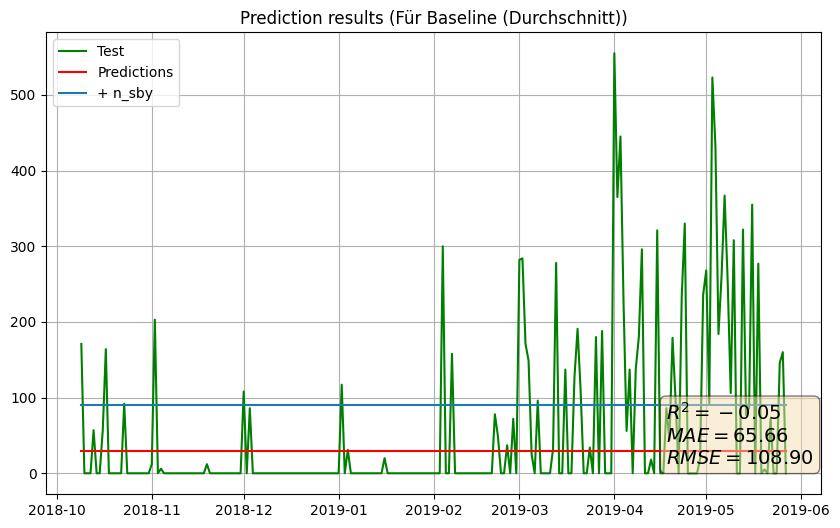

{'Anteil an Tagen mit Unterbesetzung (%)': 28.13852813852814,
 'Anteil an Tagen mit Überbesetzung (%)': 71.86147186147186,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.0,
 'Durchschnittliche Überbesetzung': 29.289751841241184,
 'Durchschnittliche Unterbesetzung': 158.52850580472733,
 'Median Überbesetzung': 29.99457111834962,
 'Median Unterbesetzung': 134.00542888165037,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 29.994571118349608,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': -23.55954143576295}

In [6]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, root_mean_squared_error
import matplotlib.pyplot as plt

def plot_regression_predictions(y_true: pd.DataFrame, y_pred: pd.DataFrame, y_train: pd.DataFrame = None, annotation : str = "", additional_column_df : pd.DataFrame = None) -> None:
    
    # Metrics
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)

    mape = mean_absolute_percentage_error(y_true, y_pred)

    # Plot 
    plt.figure(figsize=(10, 6))
    plt.title(f'Prediction results' + (f" ({annotation})" if annotation else ""))

    if y_train is not None:
        plt.plot(y_train.index, y_train, label='Train', color='blue')

    plt.plot(y_true.index, y_true, label='Test', color='green')
    plt.plot(y_true.index, y_pred, label='Predictions', color='red')

    if additional_column_df is not None:

        max_value = max([
        y_true.select_dtypes(include=[float, int]).max().max(),
        y_pred.select_dtypes(include=[float, int]).max().max(),
        additional_column_df.select_dtypes(include=[float, int]).max().max(),
        ])

        for column in additional_column_df.columns:
            if additional_column_df[column].dtype == bool:
                plt.plot(additional_column_df.index, additional_column_df[column].astype(int) * max_value, label =  "+ " +column + " (bool)", linestyle="dotted")
            else:
                plt.plot(additional_column_df.index, additional_column_df[column], label = "+ " + column)

    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)

    textstr = '\n'.join((
        r'$R^2=%.2f$' % (r2, ),
        r'$MAE=%.2f$' % (mae, ),
        r'$RMSE=%.2f$' % (rmse, )))

    print(textstr)

    plt.text(0.8, 0.2, textstr, transform=plt.gca().transAxes, fontsize=14,
        verticalalignment='top', bbox=props)

    plt.legend()
    plt.grid()
    plt.show()


plot_regression_predictions(test[[target_column_name]], test[["baseline_pred"]],  additional_column_df=test[["n_sby"]], annotation="Für Baseline (Durchschnitt)")

display(calculate_custom_personal_metrics(test, "sby_need", "baseline_pred"))

# Modeling

In [7]:
target_column_name = 'calls' #'sby_need'

usable_columns = ["day_of_week", "day_of_month", "day_of_year", "year"]

In [8]:
from sklearn.model_selection import train_test_split


# Prepare features and target
X = df[usable_columns]
y = df[target_column_name]

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False) # shuffle = False -> to keep the order of data

In [9]:

# Models used in comparision
from sklearn.ensemble import StackingRegressor, RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import BaggingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

# Additional models, which are not from sklearn
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Own classes
from app.sklearn_keras_wrapper import LSTMModelWrapper, GRUModelWrapper, CNNModelWrapper, TDNNModelWrapper, TransformerModelWrapper

shared_regularization_for_underestimation = 50

models = {

    "LSTM" : LSTMModelWrapper(historical_data_for_sequence=X_train[-30:], regularization_for_underestimation=shared_regularization_for_underestimation),
    "GRU" : GRUModelWrapper(historical_data_for_sequence=X_train[-30:], regularization_for_underestimation=shared_regularization_for_underestimation),
    "CNN" : CNNModelWrapper(historical_data_for_sequence=X_train[-30:], regularization_for_underestimation=shared_regularization_for_underestimation),
    "TDNN" : TDNNModelWrapper(historical_data_for_sequence=X_train[-30:], regularization_for_underestimation=shared_regularization_for_underestimation),
    "Transformer" : TransformerModelWrapper(historical_data_for_sequence=X_train[-30:], regularization_for_underestimation=shared_regularization_for_underestimation),

    'Linear Regression': LinearRegression(),
    
    'Decision Tree': DecisionTreeRegressor(),
    
    'Random Forest': RandomForestRegressor(
        #n_estimators=200, 
        #max_depth=10, 
        #min_samples_split=10, 
        #min_samples_leaf=5, 
        #bootstrap=True, 
        #random_state=42, 
        #n_jobs=-1
    ),
    
    'Gradient Boosting': GradientBoostingRegressor(
        #n_estimators=200, 
        #learning_rate=0.05, 
        #max_depth=4, 
        #subsample=0.8, 
        #random_state=42
    ),
    
    'Lasso Regression': Lasso(
        alpha=0.01, 
        max_iter=1000, 
        random_state=42
    ),
    
    'Ridge Regression': Ridge(
        alpha=1.0, 
        random_state=42
    ),
    
    'XGBoost': XGBRegressor(
        #n_estimators=200, 
        #learning_rate=0.05, 
        #max_depth=4, 
        #subsample=0.8, 
        #colsample_bytree=0.8, 
        #random_state=42, 
        #n_jobs=-1
    ),
    
    # # Polynomial Regression
    # 'Polynomial Regression (8)': Pipeline([
    #     ('poly', PolynomialFeatures(degree=8)),
    #     ('linear', LinearRegression())
    # ]),
    
    # 'Polynomial Ridge Regression (8)': Pipeline([
    #     ('poly', PolynomialFeatures(degree=8)),
    #     ('ridge', Ridge(alpha=1.0))
    # ]),
    'LightGBM': LGBMRegressor(random_state=42),
    # 'Bagging Regressor': BaggingRegressor(
    #     n_estimators=50,
    #     random_state=42,
    #     n_jobs=-1
    # ),
    
    # 'HistGradient Boosting': HistGradientBoostingRegressor(
    #     loss='absolute_error',
    #     learning_rate=0.05,
    #     max_iter=100,
    #     max_depth=4,
    #     random_state=42
    # )
}


2024-09-15 21:25:49.327824: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-09-15 21:25:49.342282: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-09-15 21:25:49.346658: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-09-15 21:25:49.357733: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-09-15 21:25:50.242429: W tensorflow/compiler/tf2

## Comparision

In [10]:
import numpy as np
import time
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.preprocessing import MinMaxScaler


def compare_regression_models(models, X_train, y_train, X_test, y_test, print_results : bool = False, sorted_by = "R2", sorted_asc=False, custom_metric_func=None):

    # Train and evaluate each model
    results = {}

    for model_name, model in models.items():

        start_time = time.time()
        model.fit(X_train, y_train)
        end_time = time.time() 

        start_time_pred = time.time()
        y_pred = model.predict(X_test)
        end_time_pred = time.time() 

        results[model_name] = {
            "MAE" : mean_absolute_error(y_test, y_pred),
            "MSE" : mean_squared_error(y_test, y_pred),
            "RMSE" : np.sqrt(mean_squared_error(y_test, y_pred)),
            "R2" : r2_score(y_test, y_pred),
            "MAPE" : mean_absolute_percentage_error(y_test, y_pred),
            "Training time (s)" : end_time - start_time,
            "Prediction time (s)" : end_time_pred - start_time_pred,
        }

        # Custom metrics
        if custom_metric_func:
            custom_metrics = custom_metric_func(y_test, y_pred)
            results[model_name].update(custom_metrics)
        
        if print_results:
            print(f'{model_name} - ' + ', '.join(f'{key}: {value}' for key, value in results[model_name].items()))


    results_df = pd.DataFrame(results).T

    results_df_sorted = results_df.sort_values(by=sorted_by, ascending=sorted_asc)

    return results_df_sorted

#######

# Wrapper for calculate_custom_personal_metrics in order to us it in comparision
def custom_metrics_for_pred(y_true, y_pred):

    result_df = df.loc[y_true.index, ["n_duty", "sby_need", "n_sby", "calls"]]

    if target_column_name == "calls":

        result_df["predicted_calls" ] = y_pred

        result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.82) - row.n_duty) , axis=1)
    
        return calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc", print_results=False)

    elif target_column_name == "sby_need":
        result_df["predicted_sby_need" ] = y_pred
        return calculate_custom_personal_metrics(result_df, "sby_need", "predicted_sby_need", print_results=False)
    
    else:
        print("Custom metrics cant be calculated for this column:", target_column_name)
        return {}

#results_df_sorted = compare_regression_models(models, X_train, y_train, X_test, y_test, custom_metric_func=custom_metrics_for_pred, sorted_by="R2", sorted_asc=False)
results_df_sorted = compare_regression_models(models, X_train, y_train, X_test, y_test, custom_metric_func=custom_metrics_for_pred, sorted_by="Anteil an Tagen mit Unterbesetzung (%)", sorted_asc=True)

display(results_df_sorted)

Epoch 1/50


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - loss: 3.6827 - val_loss: 0.0766
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.1554 - val_loss: 0.0743
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.1272 - val_loss: 0.0865
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0991 - val_loss: 0.2078
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0862 - val_loss: 0.2115
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0855 - val_loss: 0.1919
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0975 - val_loss: 0.0670
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0957 - val_loss: 0.0561
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0861 - val_loss: 0.0550
Epoch 10/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0798 - val_loss: 0.0710
Epoch 11/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0752 - val_loss: 0.0773
Epoch 12/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0770 - val_l

/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - loss: 2.3470 - val_loss: 0.3197
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.3204 - val_loss: 0.1447
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1558 - val_loss: 0.0727
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.1211 - val_loss: 0.0642
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.1084 - val_loss: 0.0862
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0843 - val_loss: 0.0699
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0872 - val_loss: 0.0596
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0918 - val_loss: 0.0925
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0937 - val_loss: 0.0682
Epoch 10/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0812 - val_loss: 0.0530
Epoch 11/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0852 - val_loss: 0.0742
Epoch 12/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0917 - val_l

/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.9586 - val_loss: 0.2288
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1463 - val_loss: 0.1630
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1225 - val_loss: 0.1907
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1048 - val_loss: 0.5410
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1073 - val_loss: 0.3613
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0967 - val_loss: 0.0556
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1173 - val_loss: 0.2797
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0904 - val_loss: 0.2149
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0916 - val_loss: 0.2499
Epoch 10/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0916 - val_loss: 0.1336
Epoch 11/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0823 - val_loss: 0.1220
Epoch 12/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0930 - val_loss: 0.1165


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 3.5862 - val_loss: 0.5632
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5315 - val_loss: 0.4668
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3531 - val_loss: 0.2187
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2182 - val_loss: 0.1261
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1583 - val_loss: 0.0976
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1625 - val_loss: 0.0584
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1368 - val_loss: 0.0661
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1384 - val_loss: 0.0797
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1301 - val_loss: 0.0569
Epoch 10/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1175 - val_loss: 0.0804
Epoch 11/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1078 - val_loss: 0.0708
Epoch 12/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1219 - val_loss: 0.0793


,MAE,MSE,RMSE,R2,MAPE,Training time (s),Prediction time (s),Anteil an Tagen mit Unterbesetzung (%),Anteil an Tagen mit Überbesetzung (%),Anteil an Tagen mit perfekter Prediction (%),Durchschnittliche Überbesetzung,Durchschnittliche Unterbesetzung,Median Überbesetzung,Median Unterbesetzung,Tagesdurchschnitt Ersatzfahrer für Planung,Differenz Tagesdurchschnitt Ersatzfahrer zu Realität
CNN,1744.226082,4.172345e+06,2042.631986,-1.487617,0.229716,2.275021,0.124490,6.060606,93.506494,0.432900,173.558100,55.913633,178.673927,43.088167,212.453501,158.899389
Transformer,1889.200253,4.846161e+06,2201.399764,-1.889356,0.249296,11.122994,0.291217,7.792208,92.207792,0.000000,204.219589,87.880599,199.815489,64.526582,235.012648,181.458536
GRU,1523.054876,3.390347e+06,1841.289516,-1.021377,0.200843,19.014150,0.907509,8.225108,77.922078,13.852814,156.927667,61.734040,153.282443,51.751437,170.757720,117.203607
TDNN,1500.005273,3.262808e+06,1806.324403,-0.945337,0.197052,2.551679,0.100889,9.956710,77.922078,12.121212,151.749624,72.895968,144.323211,65.184382,164.542533,110.988420
LSTM,1336.430158,2.714607e+06,1647.606585,-0.618491,0.177356,18.869169,0.824449,11.255411,67.965368,20.779221,125.489597,72.735468,126.917562,76.230274,130.656903,77.102790
Decision Tree,1259.402597,2.437581e+06,1561.275353,-0.453323,0.146290,0.003011,0.000599,27.272727,11.688312,61.038961,122.204088,163.557466,162.655602,128.000000,23.231126,-30.322987
Linear Regression,977.281052,1.366125e+06,1168.813406,0.185495,0.123135,0.001308,0.000548,30.303030,9.523810,60.173160,34.889055,154.409977,32.110054,137.566502,10.085978,-43.468135
Lasso Regression,977.277885,1.366112e+06,1168.808035,0.185503,0.123135,0.001275,0.000510,30.303030,9.523810,60.173160,34.881712,154.412654,32.102812,137.571024,10.084467,-43.469646
Ridge Regression,977.076292,1.365311e+06,1168.465331,0.185980,0.123083,0.001143,0.000507,30.303030,9.523810,60.173160,34.471223,154.569029,31.698217,137.818152,9.997986,-43.556126
XGBoost,1111.588546,1.866803e+06,1366.309986,-0.113017,0.127091,1.966512,0.008431,30.735931,1.731602,67.532468,54.211106,155.229055,34.603196,125.080702,6.781738,-46.772374


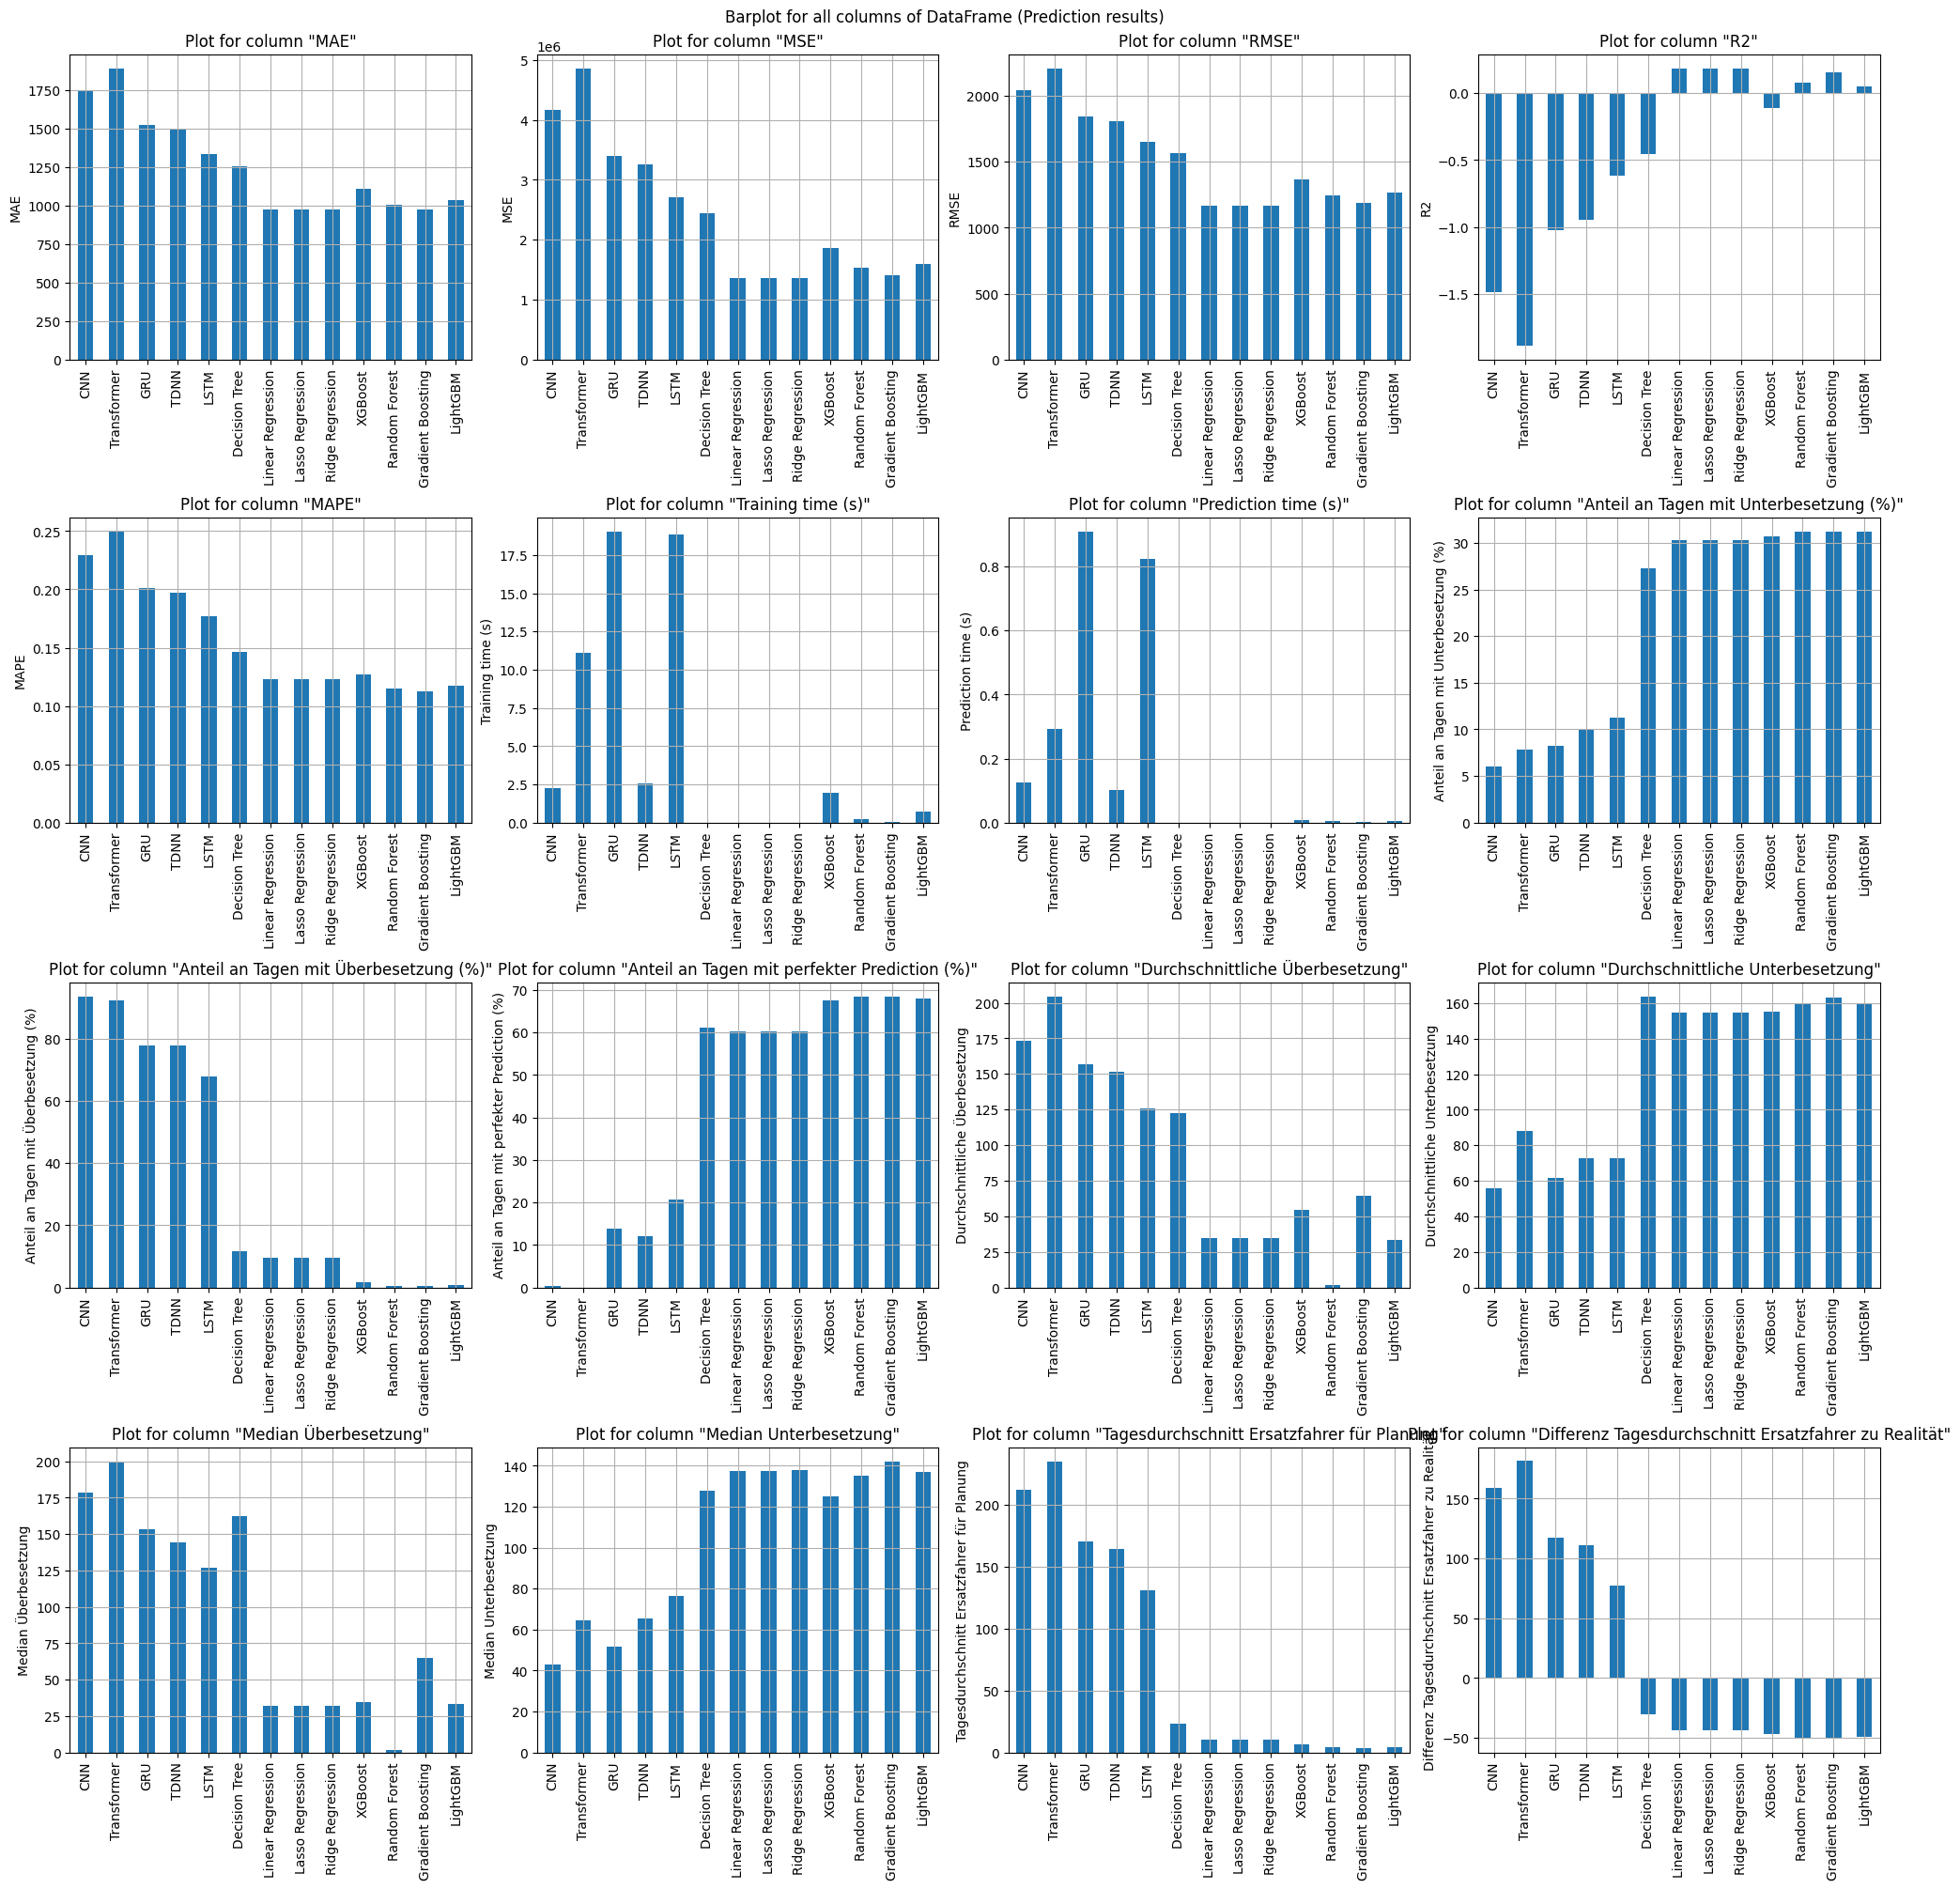

In [11]:
import matplotlib.pyplot as plt

import math
from typing import List, Optional

def barplot_columns_in_subplots(df : pd.DataFrame, columns: Optional[List[str]] = None, annotation: str = "") -> None:

    if columns is None:
        columns = df.columns

    # number of columns in datafram
    num_columns = len(columns)

    # number of rows and columns for the subplots
    if num_columns > 2:
        num_rows = math.ceil(math.sqrt(num_columns))
        num_cols = math.ceil(num_columns / num_rows)
    else:
        num_rows = 1
        num_cols = num_columns

    # Create subplots
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, 20), constrained_layout=True)
    fig.suptitle(f'Barplot for all columns of DataFrame' + (f" ({annotation})" if annotation else ""), fontsize=12)

    # Plots für jede Spalte erstellen
    for i, column in enumerate(columns):
        if num_columns > 2:
            row = i // num_cols
            col = i % num_cols
            ax = axes[row, col]
        else:
            ax = axes[i] if num_columns > 1 else axes
        if df[column].dtype == bool:
            df[column].astype(int).plot(kind='bar', ax=ax, title=f'Plot for column "{column}" (bool)')
        else:
            df[column].plot(kind='bar', ax=ax, title=f'Plot for column "{column}"')
        ax.set_xlabel(df.index.name)
        ax.set_ylabel(column)
        ax.grid()

    # Remove empty Subplots
    for j in range(i + 1, num_rows * num_cols):
        fig.delaxes(axes.flatten()[j])

    plt.show()

####

barplot_columns_in_subplots(results_df_sorted, annotation="Prediction results")


In [12]:
# Select the best model
best_model_name = results_df_sorted.index[0]
best_model_results = results_df_sorted.loc[best_model_name]

best_model = models[best_model_name]

print(f'Best Model: {best_model_name}')
print(best_model_results)

Best Model: CNN
MAE                                                     1.744226e+03
MSE                                                     4.172345e+06
RMSE                                                    2.042632e+03
R2                                                     -1.487617e+00
MAPE                                                    2.297161e-01
Training time (s)                                       2.275021e+00
Prediction time (s)                                     1.244898e-01
Anteil an Tagen mit Unterbesetzung (%)                  6.060606e+00
Anteil an Tagen mit Überbesetzung (%)                   9.350649e+01
Anteil an Tagen mit perfekter Prediction (%)            4.329004e-01
Durchschnittliche Überbesetzung                         1.735581e+02
Durchschnittliche Unterbesetzung                        5.591363e+01
Median Überbesetzung                                    1.786739e+02
Median Unterbesetzung                                   4.308817e+01
Tagesdurchschnitt 

In [13]:
### 
# To-Do: Function to do everything in one step: split, compare, print results, ... save_to_folder for set

# Idea for other use cases: To fast comparision with different feature and target data sets

## Feature importances

In [14]:
import numpy as np
import pandas as pd

def extract_features_from_model(model, X_test, plot_results = False):

    feature_names = X_test.columns if hasattr(X_test, 'columns') else [f'Feature {i}' for i in range(X_test.shape[1])]

    if hasattr(model, "feature_importances_"):
        # Feature Importance for the best model
        importances = model.feature_importances_
    elif hasattr(model, "coef_"):
        importances = np.abs(model.coef_)
    else:
        raise ValueError("Model does not have feature_importances_ or coef_ attributes.")
    
    # Create a DataFrame with feature names and their importances
    feature_importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    })
    
    # Sort the DataFrame by importance
    feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)

    if plot_results:
        plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='skyblue')
        plt.xlabel('Importance')
        plt.ylabel('Feature')
        plt.title('Feature Importance')
        plt.gca().invert_yaxis()
        plt.show()
    
    return feature_importance_df


####
try:
    feature_importance_df = extract_features_from_model(best_model, X_train, plot_results=True)

    display(feature_importance_df)
except ValueError as e:
    print("Error:", e)


Error: Model does not have feature_importances_ or coef_ attributes.


## Preditction and test comparision on best model

In [15]:
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

Epoch 1/50


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 2.6232 - val_loss: 1.1459
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1590 - val_loss: 0.1184
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1165 - val_loss: 0.1976
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1220 - val_loss: 0.3509
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1057 - val_loss: 0.2647
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0882 - val_loss: 0.1611
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0940 - val_loss: 0.0974
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0874 - val_loss: 0.1170
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0807 - val_loss: 0.1671
Epoch 10/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0887 - val_loss: 0.0888
Epoch 11/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0894 - val_loss: 0.1196
Epoch 12/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0811 - val_loss: 0.1559


In [16]:
def create_result_df(y_test, y_pred, orig_df, target_column_name):
    result_df = orig_df.loc[y_test.index, ["n_duty", "sby_need", "n_sby", "calls"]]
    result_df["predicted_" + target_column_name] = y_pred

    #Calculate sby_need from calls
    if target_column_name == "calls":
        result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.82) - row.n_duty) , axis=1)

    return(result_df)


####

result_df = create_result_df(y_test, y_pred_best, df, target_column_name)

display(result_df)

,n_duty,sby_need,n_sby,calls,predicted_calls,sby_need_calc
date,,,,,,
2018-10-09,1900,171.0,90,9870.0,9779.994324,129.044466
2018-10-10,1900,0.0,90,7896.0,9741.562202,121.070996
2018-10-11,1900,0.0,90,7302.0,9604.775597,92.692032
2018-10-12,1900,0.0,90,7506.0,9282.575478,25.845535
2018-10-13,1900,57.0,90,9318.0,9104.962761,0.000000
...,...,...,...,...,...,...
2019-05-23,1900,0.0,90,8544.0,9590.718681,89.775660
2019-05-24,1900,0.0,90,8814.0,9271.842751,23.618828
2019-05-25,1900,146.0,90,9846.0,9099.057152,0.000000


$R^2=-0.28$
$MAE=1182.34$
$RMSE=1467.79$


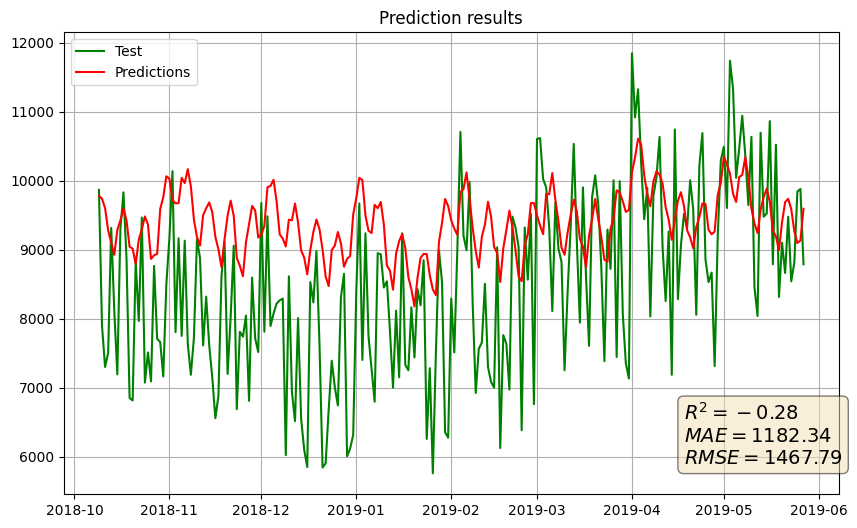

$R^2=0.18$
$MAE=65.15$
$RMSE=96.20$


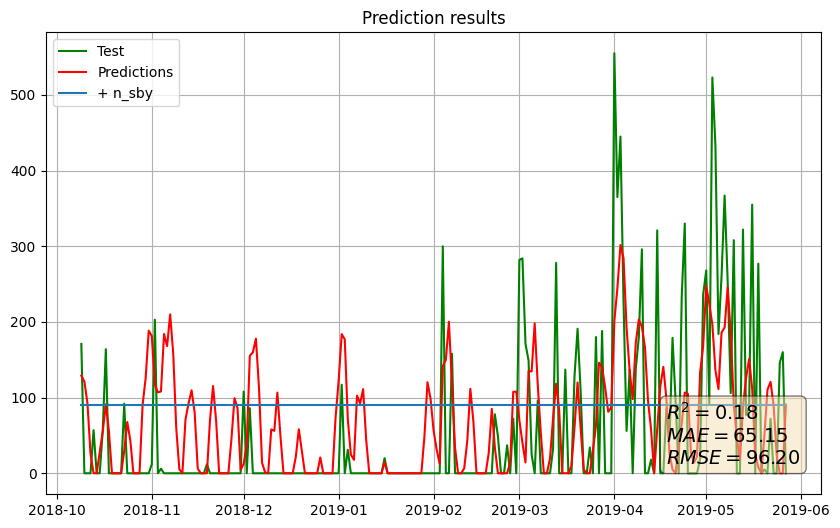

{'Anteil an Tagen mit Unterbesetzung (%)': 22.07792207792208,
 'Anteil an Tagen mit Überbesetzung (%)': 51.94805194805194,
 'Anteil an Tagen mit perfekter Prediction (%)': 25.97402597402597,
 'Durchschnittliche Überbesetzung': 75.01549052532602,
 'Durchschnittliche Unterbesetzung': 118.56567070709382,
 'Median Überbesetzung': 67.69169930105875,
 'Median Unterbesetzung': 95.5646899844603,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 66.34636215141704,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': 12.792249597304483}

In [17]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, root_mean_squared_error
import matplotlib.pyplot as plt

def plot_regression_predictions(y_true: pd.DataFrame, y_pred: pd.DataFrame, y_train: pd.DataFrame = None, annotation : str = "", additional_column_df : pd.DataFrame = None) -> None:
    
    # Metrics
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)

    mape = mean_absolute_percentage_error(y_true, y_pred)

    # Plot 
    plt.figure(figsize=(10, 6))
    plt.title(f'Prediction results' + (f" ({annotation})" if annotation else ""))

    if y_train is not None:
        plt.plot(y_train.index, y_train, label='Train', color='blue')

    plt.plot(y_true.index, y_true, label='Test', color='green')
    plt.plot(y_true.index, y_pred, label='Predictions', color='red')

    if additional_column_df is not None:

        max_value = max([
        y_true.select_dtypes(include=[float, int]).max().max(),
        y_pred.select_dtypes(include=[float, int]).max().max(),
        additional_column_df.select_dtypes(include=[float, int]).max().max(),
        ])

        for column in additional_column_df.columns:
            if additional_column_df[column].dtype == bool:
                plt.plot(additional_column_df.index, additional_column_df[column].astype(int) * max_value, label =  "+ " +column + " (bool)", linestyle="dotted")
            else:
                plt.plot(additional_column_df.index, additional_column_df[column], label = "+ " + column)

    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)

    textstr = '\n'.join((
        r'$R^2=%.2f$' % (r2, ),
        r'$MAE=%.2f$' % (mae, ),
        r'$RMSE=%.2f$' % (rmse, )))

    print(textstr)

    plt.text(0.8, 0.2, textstr, transform=plt.gca().transAxes, fontsize=14,
        verticalalignment='top', bbox=props)

    plt.legend()
    plt.grid()
    plt.show()

####

plot_regression_predictions(result_df[[target_column_name]], result_df[["predicted_" + target_column_name]])

if target_column_name == "calls":
    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]])
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

## Customize best models

### Gradient Boosting (not working as expected)

,n_duty,sby_need,n_sby,calls,predicted_calls,sby_need_calc
date,,,,,,
2018-10-09,1900,171.0,90,9870.0,9130.401726,0.0
2018-10-10,1900,0.0,90,7896.0,8851.080360,0.0
2018-10-11,1900,0.0,90,7302.0,8734.946191,0.0
2018-10-12,1900,0.0,90,7506.0,8451.368894,0.0
2018-10-13,1900,57.0,90,9318.0,8313.449347,0.0
...,...,...,...,...,...,...
2019-05-23,1900,0.0,90,8544.0,8424.434244,0.0
2019-05-24,1900,0.0,90,8814.0,8245.931005,0.0
2019-05-25,1900,146.0,90,9846.0,7887.996882,0.0


$R^2=0.16$
$MAE=978.36$
$RMSE=1188.75$


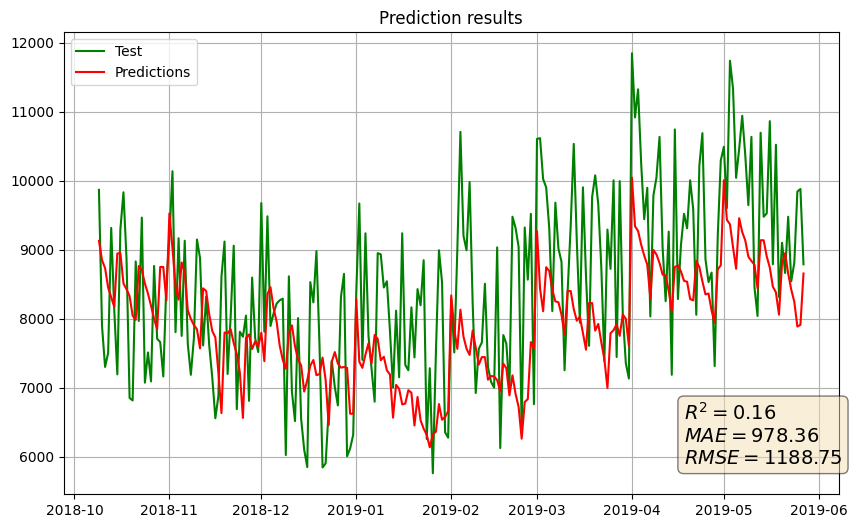

$R^2=-0.11$
$MAE=51.05$
$RMSE=111.85$


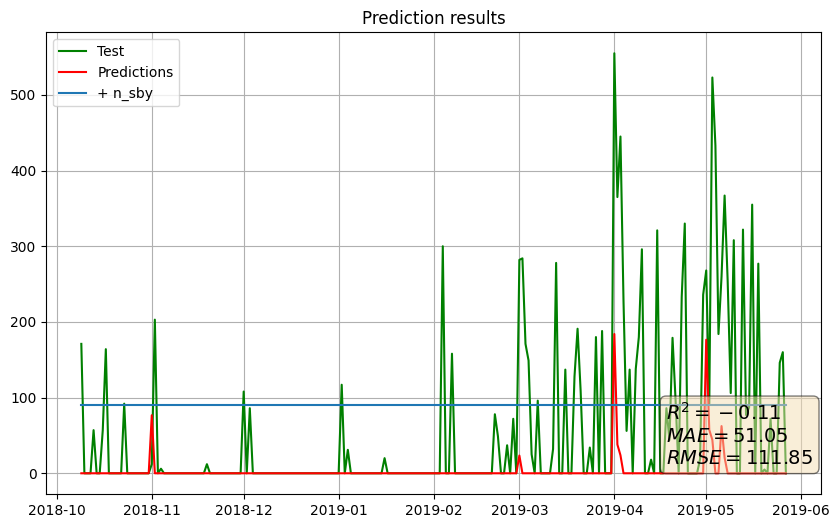

{'Anteil an Tagen mit Unterbesetzung (%)': 31.16883116883117,
 'Anteil an Tagen mit Überbesetzung (%)': 0.4329004329004329,
 'Anteil an Tagen mit perfekter Prediction (%)': 68.3982683982684,
 'Durchschnittliche Überbesetzung': 64.70123964414529,
 'Durchschnittliche Unterbesetzung': 162.90017556323636,
 'Median Überbesetzung': 64.70123964414529,
 'Median Unterbesetzung': 142.0,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 3.060123805589293,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': -50.493988748523265}

In [18]:
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor

class CustomGradientBoostingRegressor(GradientBoostingRegressor):
    def __init__(self, underestimation_penalty=5, overestimation_penalty=1, n_estimators=100, learning_rate=0.1, max_depth=3, **kwargs):
        self.underestimation_penalty = underestimation_penalty
        self.overestimation_penalty = overestimation_penalty
        super().__init__(n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth, **kwargs)

    def fit(self, X, y, sample_weight=None):
        # Initial fit to get initial predictions
        super().fit(X, y, sample_weight)
        y_pred = self.predict(X)
        
        # Custom boosting iterations
        for i in range(self.n_estimators):
            residual = self.custom_loss(y, y_pred, self.underestimation_penalty, self.overestimation_penalty)
            tree = DecisionTreeRegressor(max_depth=self.max_depth, random_state=self.random_state)
            tree.fit(X, residual, sample_weight=sample_weight)
            y_pred += self.learning_rate * tree.predict(X)
        
        return self

    # Definiere die benutzerdefinierte Verlustfunktion mit variabler Bestrafung
    def custom_loss(self, y_true, y_pred, underestimation_penalty, overestimation_penalty):
        residual = y_true - y_pred
        return np.where(residual < 0, -underestimation_penalty * residual, -overestimation_penalty * residual)

# Initialisiere das Modell mit der benutzerdefinierten Verlustfunktion
model = CustomGradientBoostingRegressor(underestimation_penalty=1, overestimation_penalty=1, random_state=42)

# Trainiere das Modell
model.fit(X_train, y_train)

y_pred = model.predict(X_test)


####

result_df = create_result_df(y_test, y_pred, df, target_column_name)

display(result_df)


plot_regression_predictions(result_df[[target_column_name]], result_df[["predicted_" + target_column_name]])

if target_column_name == "calls":
    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]])
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

### LightGBM

[LightGBM] [Warning] Using self-defined objective function
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.031740 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 298
[LightGBM] [Info] Number of data points in the train set: 921, number of used features: 4
[LightGBM] [Warning] Using self-defined objective function


,n_duty,sby_need,n_sby,calls,predicted_calls,sby_need_calc
date,,,,,,
2018-10-09,1900,171.0,90,9870.0,9678.864472,108.063169
2018-10-10,1900,0.0,90,7896.0,9223.781704,13.647656
2018-10-11,1900,0.0,90,7302.0,8954.855833,0.000000
2018-10-12,1900,0.0,90,7506.0,8901.357809,0.000000
2018-10-13,1900,57.0,90,9318.0,8421.597444,0.000000
...,...,...,...,...,...,...
2019-05-23,1900,0.0,90,8544.0,9334.319543,36.580818
2019-05-24,1900,0.0,90,8814.0,8920.898076,0.000000
2019-05-25,1900,146.0,90,9846.0,8808.310587,0.000000


$R^2=0.42$
$MAE=842.58$
$RMSE=986.82$


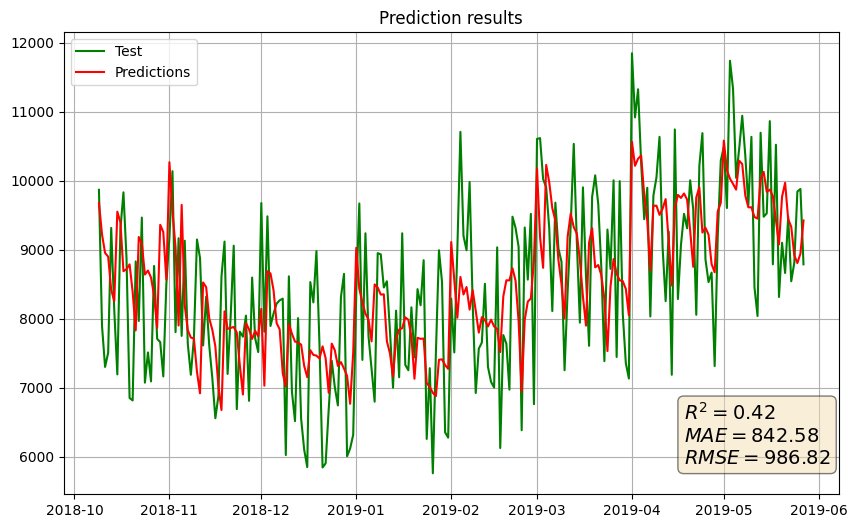

$R^2=0.36$
$MAE=43.97$
$RMSE=84.99$


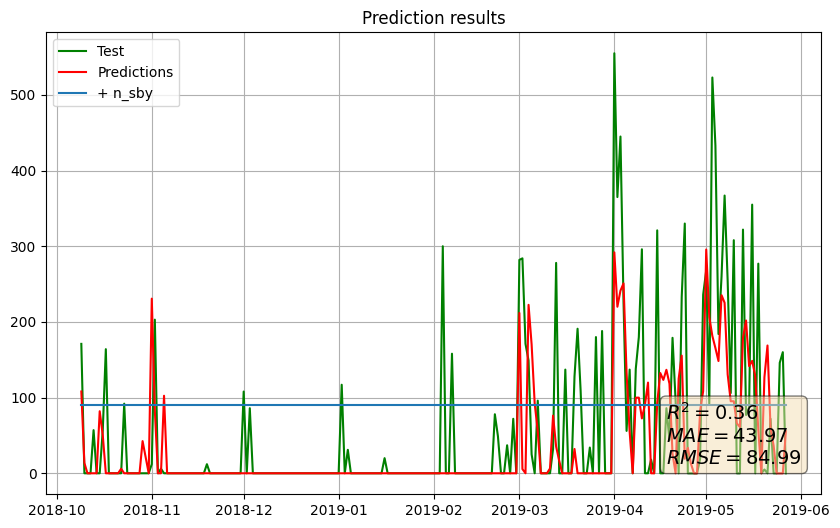

{'Anteil an Tagen mit Unterbesetzung (%)': 25.541125541125542,
 'Anteil an Tagen mit Überbesetzung (%)': 15.584415584415584,
 'Anteil an Tagen mit perfekter Prediction (%)': 58.87445887445888,
 'Durchschnittliche Überbesetzung': 76.42470901992942,
 'Durchschnittliche Unterbesetzung': 125.53299886846267,
 'Median Überbesetzung': 69.75544926907276,
 'Median Unterbesetzung': 117.0,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 33.401915980424945,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': -20.15219657368761}

In [19]:
import lightgbm as lgb
import numpy as np


# Definiere deine benutzerdefinierte Bewertungsmetrik
def custom_loss(y_pred, dataset):

    underestimation_penalty = 100
    overestimation_penalty = 1

    y_true = dataset.get_label()
    residual = (y_true - y_pred).astype("float")
    grad = np.where(residual > 0, -underestimation_penalty * residual, -overestimation_penalty * residual)  # Gradientenberechnung
    hess = np.where(residual > 0, underestimation_penalty, overestimation_penalty)  # Hesse-Matrix
    return grad, hess



# Erstelle das Dataset für LightGBM
train_data = lgb.Dataset(X_train, label=y_train)
valid_data = lgb.Dataset(X_test, label=y_test, reference=train_data)

# Definiere die Parameter
params = {
    'objective': 'regression',
    'metric': 'custom'
}

# Trainiere das Modell
bst = lgb.train(params, train_data, fobj=custom_loss, valid_sets=[train_data]) # für fobj LightGBM gedwongraded auf Version 3.2.1

# Vorhersagen machen
y_pred_best = bst.predict(X_test)

####

result_df = create_result_df(y_test, y_pred_best, df, target_column_name)

display(result_df)

plot_regression_predictions(result_df[[target_column_name]], result_df[["predicted_" + target_column_name]])

if target_column_name == "calls":
    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]])
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

### LSTM

Epoch 1/100


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - loss: 0.8956 - val_loss: 0.0437
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0831 - val_loss: 0.0761
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0659 - val_loss: 0.0893
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0612 - val_loss: 0.0569
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0557 - val_loss: 0.1074
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0601 - val_loss: 0.0596
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0509 - val_loss: 0.0402
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0499 - val_loss: 0.0458
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0517 - val_loss: 0.0477
Epoch 10/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0495 - val_loss: 0.0434
Epoch 11/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0552 - val_loss: 0.0595
Epoch 12/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0

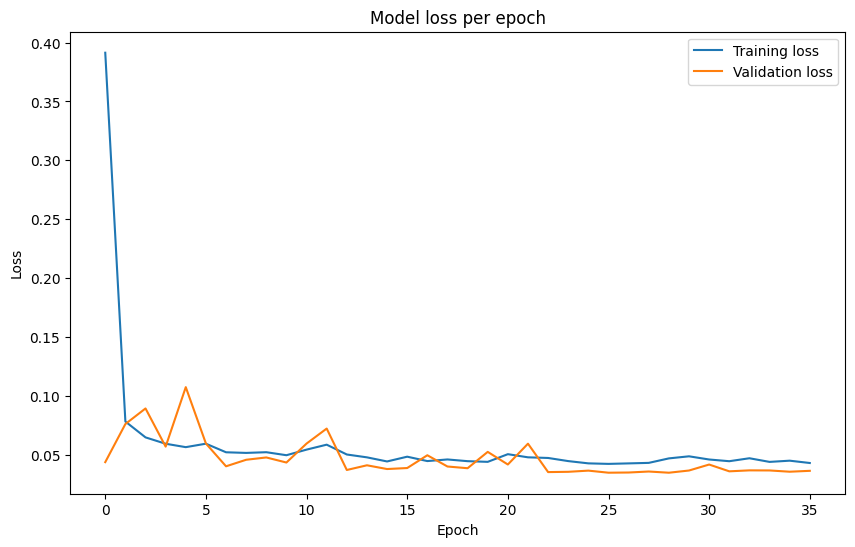

In [20]:
from app.sklearn_keras_wrapper import LSTMModelWrapper

lstm_model = LSTMModelWrapper(historical_data_for_sequence=X_train[-30:], regularization_for_underestimation=10)
lstm_model.fit(X_train, y_train, epochs=100)
#lstm_model = LSTMModelWrapper.load("lstm_model")

predictions = lstm_model.predict(X_test)
score = lstm_model.score(X_test, y_test)
lstm_model.plot_loss()

,n_duty,sby_need,n_sby,calls,predicted_calls,sby_need_calc
date,,,,,,
2018-10-09,1900,171.0,90,9870.0,9452.733124,61.147951
2018-10-10,1900,0.0,90,7896.0,9513.156029,73.683823
2018-10-11,1900,0.0,90,7302.0,9233.806801,15.727552
2018-10-12,1900,0.0,90,7506.0,9022.547768,0.000000
2018-10-13,1900,57.0,90,9318.0,8920.924324,0.000000
...,...,...,...,...,...,...
2019-05-23,1900,0.0,90,8544.0,9777.264175,128.478045
2019-05-24,1900,0.0,90,8814.0,9546.131332,80.525173
2019-05-25,1900,146.0,90,9846.0,9440.482246,58.606275


$R^2=0.09$
$MAE=1000.24$
$RMSE=1233.69$


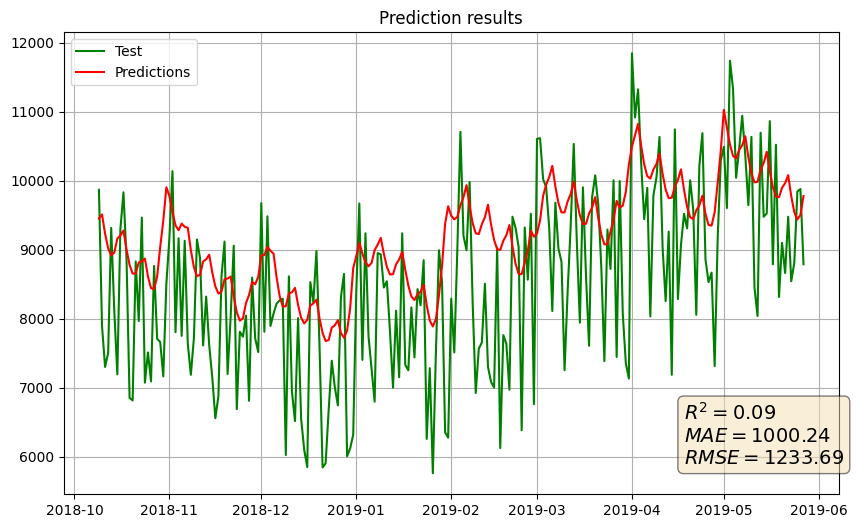

$R^2=0.34$
$MAE=55.59$
$RMSE=86.63$


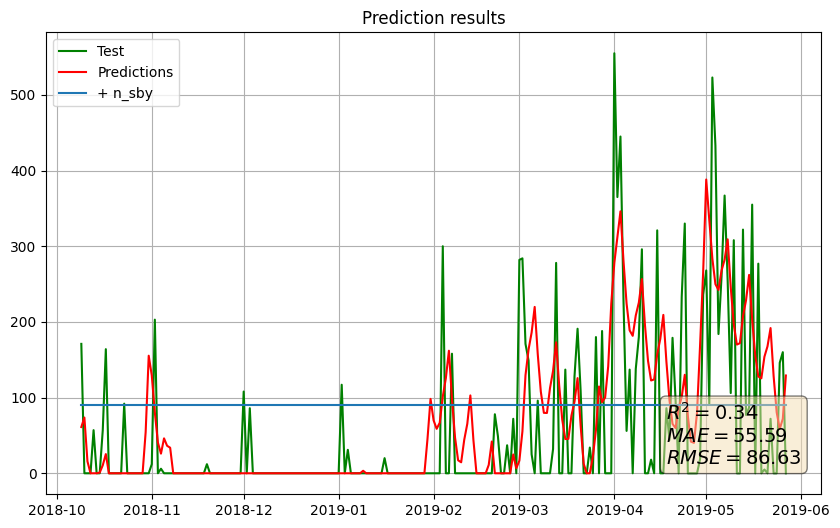

{'Anteil an Tagen mit Unterbesetzung (%)': 20.346320346320347,
 'Anteil an Tagen mit Überbesetzung (%)': 37.66233766233766,
 'Anteil an Tagen mit perfekter Prediction (%)': 41.99134199134199,
 'Durchschnittliche Überbesetzung': 91.73044876809634,
 'Durchschnittliche Unterbesetzung': 103.41398947550661,
 'Median Überbesetzung': 79.69719502935754,
 'Median Unterbesetzung': 92.0,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 67.06100232673407,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': 13.506889772621513}

In [21]:
result_df = create_result_df(y_test, predictions, df, target_column_name)

display(result_df)


plot_regression_predictions(result_df[[target_column_name]], result_df[["predicted_" + target_column_name]])

if target_column_name == "calls":
    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]])
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

In [22]:
lstm_model.save("../../app/models/lstm")

### GRU

Epoch 1/100


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - loss: 0.9802 - val_loss: 0.0728
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.1441 - val_loss: 0.0606
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.1055 - val_loss: 0.0505
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0791 - val_loss: 0.0459
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0934 - val_loss: 0.0437
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0697 - val_loss: 0.0832
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0734 - val_loss: 0.0438
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0783 - val_loss: 0.0693
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0774 - val_loss: 0.0632
Epoch 10/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0741 - val_loss: 0.1137
Epoch 11/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0653 - val_loss: 0.0652
Epoch 12/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0

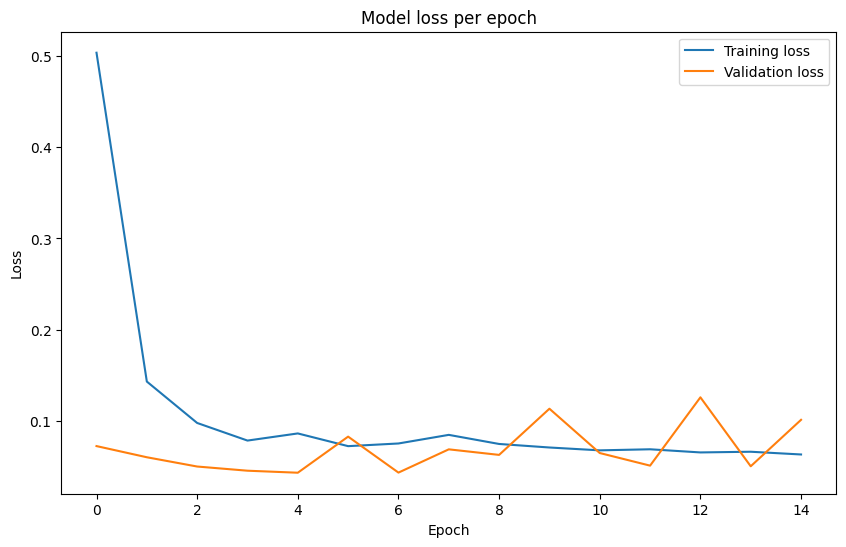

In [23]:
from app.sklearn_keras_wrapper import GRUModelWrapper

gru_model = GRUModelWrapper(historical_data_for_sequence=X_train[-30:], regularization_for_underestimation=20)
gru_model.fit(X_train, y_train, epochs=100)
#gru_model = GRUModelWrapper.load("gru")

predictions = gru_model.predict(X_test)
score = gru_model.score(X_test, y_test)
gru_model.plot_loss()

,n_duty,sby_need,n_sby,calls,predicted_calls,sby_need_calc
date,,,,,,
2018-10-09,1900,171.0,90,9870.0,10027.828995,180.462447
2018-10-10,1900,0.0,90,7896.0,10108.030037,197.101667
2018-10-11,1900,0.0,90,7302.0,9920.716553,158.239949
2018-10-12,1900,0.0,90,7506.0,9753.887009,123.628010
2018-10-13,1900,57.0,90,9318.0,9650.606255,102.200468
...,...,...,...,...,...,...
2019-05-23,1900,0.0,90,8544.0,10283.031326,233.408989
2019-05-24,1900,0.0,90,8814.0,10108.804550,197.262355
2019-05-25,1900,146.0,90,9846.0,9983.199463,171.203208


$R^2=-1.21$
$MAE=1606.64$
$RMSE=1927.04$


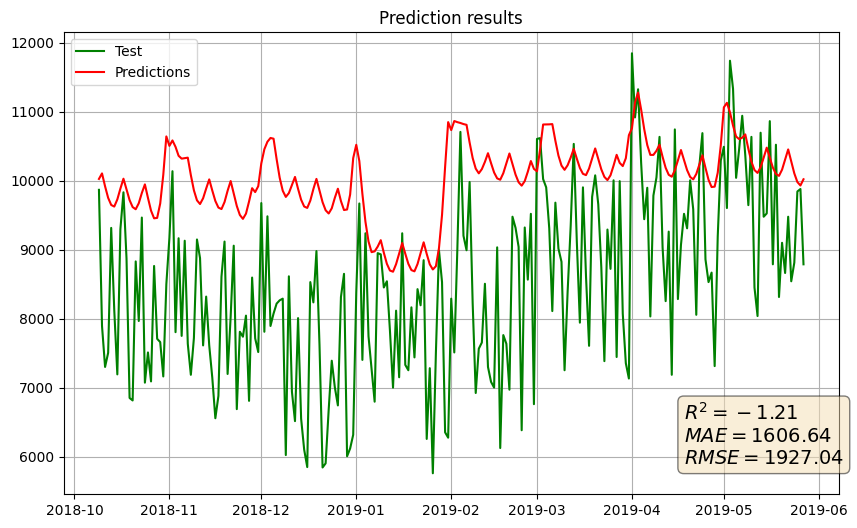

$R^2=-1.50$
$MAE=142.60$
$RMSE=168.20$


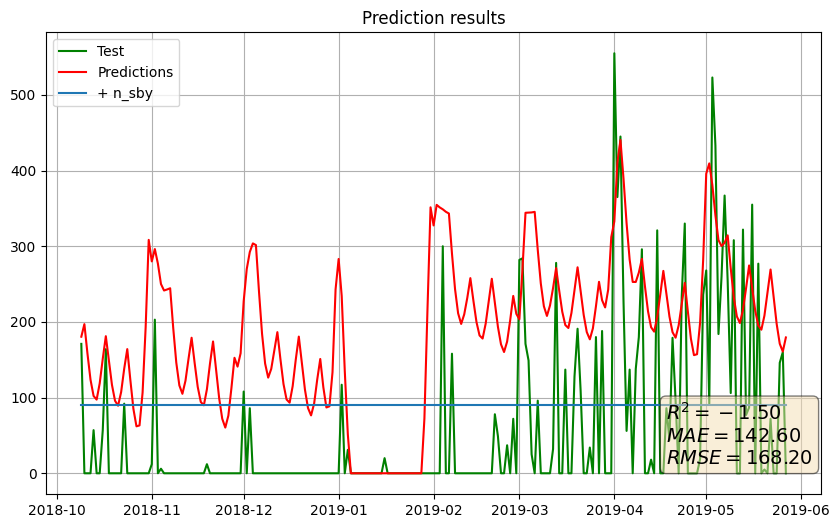

{'Anteil an Tagen mit Unterbesetzung (%)': 7.35930735930736,
 'Anteil an Tagen mit Überbesetzung (%)': 82.68398268398268,
 'Anteil an Tagen mit perfekter Prediction (%)': 9.956709956709958,
 'Durchschnittliche Überbesetzung': 166.00499304333658,
 'Durchschnittliche Unterbesetzung': 72.52582964013787,
 'Median Überbesetzung': 162.3294452334835,
 'Median Unterbesetzung': 78.4161930954806,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 185.47625353850626,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': 131.9221409843937}

In [24]:
result_df = create_result_df(y_test, predictions, df, target_column_name)

display(result_df)


plot_regression_predictions(result_df[[target_column_name]], result_df[["predicted_" + target_column_name]])

if target_column_name == "calls":
    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]])
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

In [25]:
lstm_model.save("../../app/models/gru")